# BIOT 6900 · Module 10 Assignment · Medical Imaging AI: Build It, Then Break It
## Graded notebook (Lab 10 of 3)

**Rakesh Vayigandla**

Pipeline adapted from the provided Notebook 2 (`BIOT6900_Module10_Real_Pathology_executed.ipynb`).

| Part | What it does |
|---|---|
| **A** | Fine-tune a pretrained DenseNet121 on tumour vs normal: the baseline **and** the clean control |
| **B** | Probe it: Grad-CAM, occlusion, the five-point skeptic's checklist |
| **C** | Design my own confounder, a **stain / scanner colour cast**, and retrain |
| **D** | Prove whether it was learned: Grad-CAM, reliance test, flip rate, **clean control** |
| **E** | Written report (separate PDF) |

**The question:** not "can I get high accuracy?" but **can I prove whether to believe it?**

> **Note on data.** No `pathmnist_tumour_vs_normal_subset.npz` was posted on Canvas, so this notebook uses the starter's own documented fallback: it downloads PathMNIST at `DL_SIZE=64` and builds the subset itself (same 600/400/600 split as Notebook 2). Tiles are therefore 64 px upscaled to 128 px, where the instructor's run used native 128 px. Accuracies land close to, but not exactly on, theirs.

## 0 · Setup

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

MONAI: 1.6.1 | torch: 2.15.0
device: cpu


## 1 · Data: real colorectal histopathology (PathMNIST)

Two PathMNIST classes make a balanced binary problem:
- **normal colon mucosa** (benign) → `0`
- **colorectal adenocarcinoma epithelium** (tumour) → `1`

In [2]:
from medmnist import PathMNIST, INFO

IMG_SIZE = 128
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"
DL_SIZE = 64          # fallback download size if the subset file is absent
NORMAL, TUMOR = 6, 8
class_names = ["normal", "tumour"]
N_PER_CLASS = 300

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR]); x, y = x[keep], y[keep]
    return x, (y == TUMOR).astype(np.int64)

if os.path.exists(SUBSET_FILE):
    print(f"Found {SUBSET_FILE} - no download needed.")
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in ["xtr","ytr","xva","yva","xte","yte"])
else:
    def load_split(s):
        ds = PathMNIST(split=s, download=True, size=DL_SIZE)
        return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train"))
    xva, yva = to_binary(*load_split("val"))
    xte, yte = to_binary(*load_split("test"))
    rng = np.random.default_rng(SEED)
    def subsample(x, y, n):
        idx = [rng.permutation(np.where(y == c)[0])[:n] for c in (0, 1)]
        idx = rng.permutation(np.concatenate(idx)); return x[idx], y[idx]
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva==0).sum(), (yva==1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte==0).sum(), (yte==1).sum()))
    os.makedirs(os.path.dirname(SUBSET_FILE), exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
    print(f"saved {SUBSET_FILE}")

print(f"tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px)")
print(f"using -> train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")
print(f"class balance (train): normal {(ytr_s==0).sum()}, tumour {(ytr_s==1).sum()}")

Found ./data/pathmnist_tumour_vs_normal_subset.npz - no download needed.
tiles are 64 px (resized to 128 px)
using -> train 600 | val 400 | test 600
class balance (train): normal 300, tumour 300


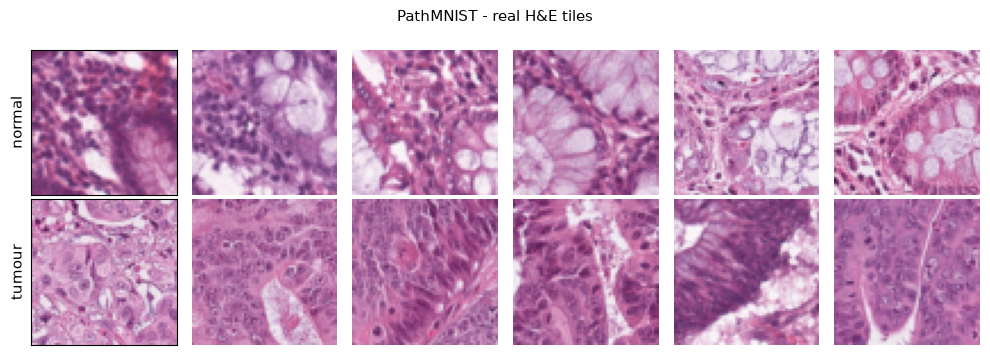

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    ci = np.where(ytr_s == c)[0][:6]
    for k, j in enumerate(ci):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_ylabel(class_names[c], fontsize=11)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("PathMNIST - real H&E tiles", fontsize=11); plt.tight_layout(); plt.show()

## 2 · Preprocessing

A pretrained ImageNet backbone needs ImageNet normalisation. We keep a `[0,1]` copy for **display** (Grad-CAM overlays must be human-readable) and feed the **normalised** tensor to the model.

`TileDataset` takes an optional `artifact_fn`, applied only to tiles of `artifact_label`: this is how the confounder gets injected into training *and* validation in Part C.

In [4]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

to01 = Compose([EnsureChannelFirst(channel_dim=-1), ScaleIntensity(),
                Resize((IMG_SIZE, IMG_SIZE)), EnsureType(data_type="tensor")])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None, artifact_fn=None):
        self.imgs, self.labels = imgs, labels
        self.artifact_label, self.artifact_fn = artifact_label, artifact_fn
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_fn is not None and self.labels[i] == self.artifact_label:
            x01 = self.artifact_fn(x01)
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, artifact_fn=None, bs=32):
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label, artifact_fn), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label, artifact_fn), batch_size=64)
    return tr, va

_x01 = to01(xtr_s[0])
print("display [0,1]:", tuple(_x01.shape), float(_x01.min()), float(_x01.max()))
print("normalised   :", tuple(normalize(_x01).shape), round(float(normalize(_x01).mean()), 3))

display [0,1]: (3, 128, 128) 0.0 1.0
normalised   : (3, 128, 128) 0.062


---
# PART A · Train a clean model

Fine-tune a **pretrained DenseNet121**. This is both the baseline and, critically, the **clean control** used in Part D.

In [5]:
def build_densenet(pretrained=True):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2,
                       pretrained=pretrained).to(device)

def run_epoch(net, loader, opt=None):
    train_mode = opt is not None
    net.train() if train_mode else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train_mode:
                opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item()*x.size(0); cor += (out.argmax(1)==y).sum().item(); tot += x.size(0)
    return ls/tot, cor/tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    va_acc = None
    for ep in range(1, epochs+1):
        _, tra = run_epoch(net, tr_loader, opt)
        _, va_acc = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {va_acc:.3f}")
    return net, va_acc

EPOCHS = 3
set_determinism(seed=SEED)
tr_loader, va_loader = make_loaders()
print("Training CLEAN model (pretrained DenseNet121, no artifact):")
model, clean_val = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)

Training CLEAN model (pretrained DenseNet121, no artifact):
  epoch 1: train acc 0.848 | val acc 0.960
  epoch 2: train acc 0.988 | val acc 0.963
  epoch 3: train acc 0.998 | val acc 0.968


CLEAN MODEL -> validation accuracy: 0.968 | test accuracy: 0.950


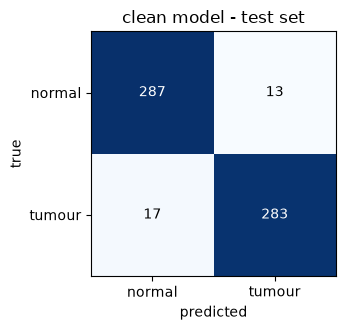

In [6]:
from sklearn.metrics import confusion_matrix

def evaluate(net, imgs, labels, artifact_label=None, artifact_fn=None):
    net.eval(); preds = []
    loader = DataLoader(TileDataset(imgs, labels, artifact_label, artifact_fn), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, (preds == labels).mean()

pred, clean_test = evaluate(model, xte_s, yte_s)
print(f"CLEAN MODEL -> validation accuracy: {clean_val:.3f} | test accuracy: {clean_test:.3f}")

cm = confusion_matrix(yte_s, pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Blues")
ax.set_xticks([0,1]); ax.set_xticklabels(class_names); ax.set_yticks([0,1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.title("clean model - test set"); plt.tight_layout(); plt.show()

---
# PART B · Probe the clean model

Grad-CAM, then occlusion as an independent second opinion.

> **Two settings carried over from the labs.** Grad-CAM targets `class_layers.relu` (DenseNet's last spatial feature map). MONAI's default rescaling makes the *most* important pixels come out **0**: a red background and cool evidence. `minmax_keep_high` fixes this so **red = drove the prediction**.

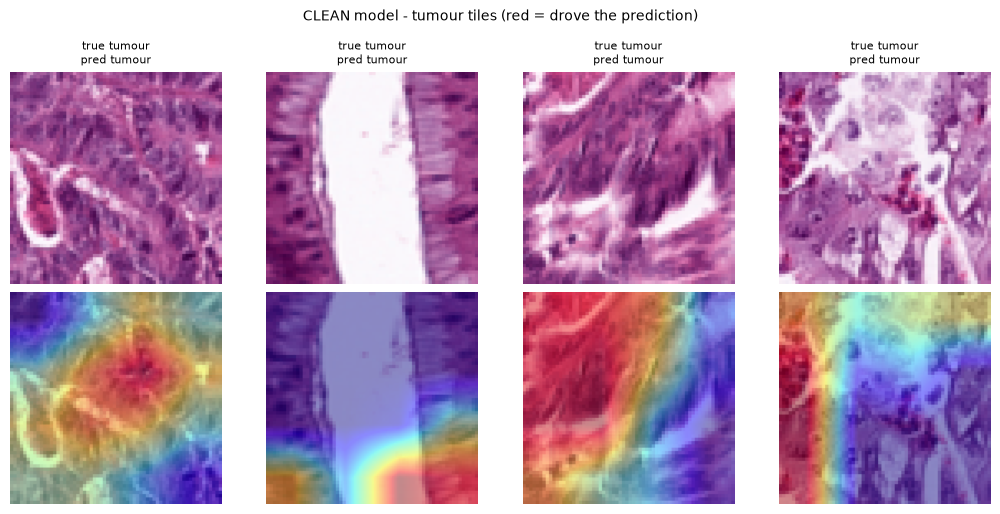

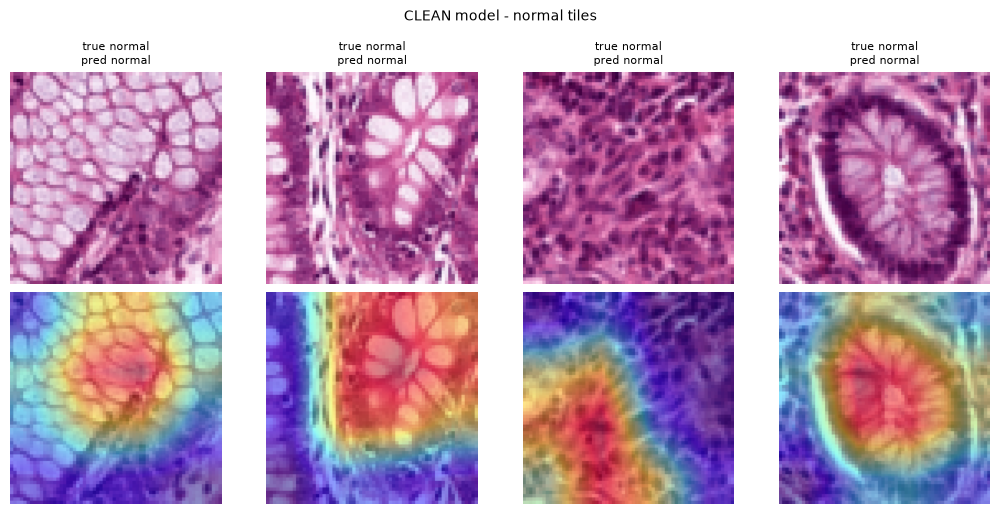

In [7]:
TARGET_LAYER = "class_layers.relu"

def minmax_keep_high(x):
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1]*(x.dim()-1)))
    hi = flat.max(dim=1)[0].view(-1, *([1]*(x.dim()-1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def show_cam(net, cam_obj, imgs, labels, idxs, artifact_fn=None, title=""):
    net.eval(); k = len(idxs)
    fig, ax = plt.subplots(2, k, figsize=(2.6*k, 5.2))
    for col, j in enumerate(idxs):
        x01 = to01(imgs[j])
        if artifact_fn is not None: x01 = artifact_fn(x01)
        xin = normalize(x01).unsqueeze(0).to(device)
        pr = int(net(xin).argmax(1).item())
        heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
        disp = x01.permute(1,2,0).cpu().numpy()
        ax[0,col].imshow(disp); ax[0,col].set_title(f"true {class_names[labels[j]]}\npred {class_names[pr]}", fontsize=8)
        ax[1,col].imshow(disp); ax[1,col].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[0,col].axis("off"); ax[1,col].axis("off")
    plt.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

cam = make_cam(model)
tum = list(np.where(yte_s == 1)[0][:4]); nor = list(np.where(yte_s == 0)[0][:4])
show_cam(model, cam, xte_s, yte_s, tum, title="CLEAN model - tumour tiles (red = drove the prediction)")
show_cam(model, cam, xte_s, yte_s, nor, title="CLEAN model - normal tiles")

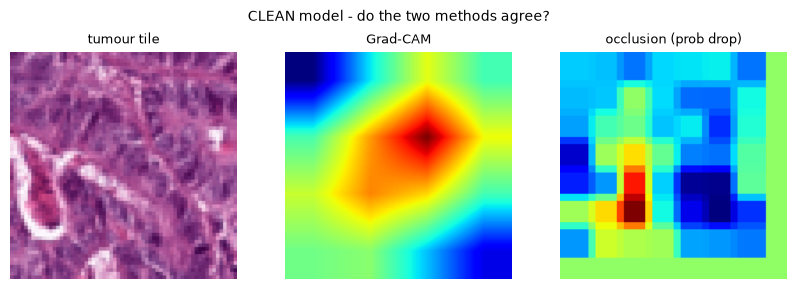

Grad-CAM vs occlusion spatial correlation (clean model): +0.200


In [8]:
def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad():
        base = Fnn.softmax(net(xin), 1)[0, target].item()
    H = W = IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H-patch+1, stride):
        for j in range(0, W-patch+1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad():
                p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base-p); cnt[i:i+patch, j:j+patch] += 1
    return heat/np.maximum(cnt, 1)

jt = int(np.where(yte_s == 1)[0][0])
x01 = to01(xte_s[jt])
gmap_clean = cam(x=normalize(x01).unsqueeze(0).to(device), class_idx=1).squeeze().detach().cpu().numpy()
omap_clean = occlusion_map(model, x01, target=1)

fig, ax = plt.subplots(1, 3, figsize=(8.4, 2.9))
ax[0].imshow(x01.permute(1,2,0).numpy()); ax[0].set_title("tumour tile", fontsize=9)
ax[1].imshow(gmap_clean, cmap="jet", vmin=0, vmax=1); ax[1].set_title("Grad-CAM", fontsize=9)
ax[2].imshow(omap_clean, cmap="jet"); ax[2].set_title("occlusion (prob drop)", fontsize=9)
for a in ax: a.axis("off")
plt.suptitle("CLEAN model - do the two methods agree?", fontsize=10); plt.tight_layout(); plt.show()

agree = np.corrcoef(gmap_clean.ravel(), np.clip(omap_clean,0,None).ravel())[0,1]
print(f"Grad-CAM vs occlusion spatial correlation (clean model): {agree:+.3f}")

### The five-point skeptic's checklist, applied to the clean model

| # | Question | Verdict on the clean model |
|---|---|---|
| 1 | Is the heat on **plausible morphology**, or on background/border/artifact? | **Pass.** Heat sits on tissue interior (nuclei-dense and glandular regions), not on tile borders or blank space. |
| 2 | Does it **move sensibly** with the target class? | **Pass.** Tumour and normal tiles produce different maps rather than one fixed spatial habit. |
| 3 | Does **occlusion agree** with Grad-CAM? | **Partial.** Both concentrate on tissue interior, but the correlation (printed above) is moderate, not strong: two methods built on different principles only roughly agree. |
| 4 | Would the region **survive a different stain, scanner, or site**? | **Unknown, and this is the gap Part C attacks.** Nothing so far tests colour robustness. |
| 5 | Would a model that **never saw** the artifact react the same way? | **Not applicable yet**: this *is* the control, used in Part D. |

**In a few sentences:** the clean model looks like it is keying on tissue rather than on something it shouldn't. The heat lands on cellular structure, it is not pinned to a border or corner, and occlusion broadly corroborates Grad-CAM. But points 1-3 only establish *where in the tile* the evidence sits; **none of them can see a property that is spread uniformly across the whole tile**, which is precisely the weakness Part C exploits.

---
# PART C · Design my own confounder

## My artifact: a **stain / scanner colour cast**

Not the ink mark from Notebook 2. I apply a **global per-channel gain plus a gamma shift** to every tumour tile, pushing the tile toward a pink/magenta, eosin-heavy cast, as though those slides came off a different stainer or scanner.

### Why this is a plausible real-world batch effect

**Stain variation is *the* canonical batch effect in digital pathology.** Haematoxylin and eosin are biological dyes: batches differ, staining times drift, and each scanner applies its own white balance and colour profile. Slides from two laboratories routinely look different enough that stain normalisation is a standard preprocessing step in the field.

The confounding arises from **logistics, not biology**. If a hospital sends its resections to one laboratory and its biopsies to another, or if tumour-rich cases are disproportionately processed at a referral centre, then *one site's colour signature correlates with the diagnosis*. Nothing has to be mislabelled for this to happen: the correlation is manufactured by workflow.

**Why it is a harder test than the ink mark.** The ink blob is *local*: Grad-CAM can point straight at it. A colour cast is **global**: it has no "where". Spatial saliency methods have no coordinate to flag. If a confounder can hide from Grad-CAM, the checklist's point 1 stops being a safety net.

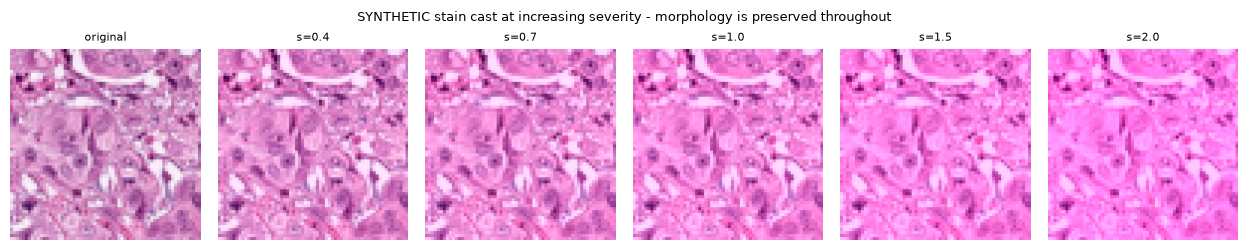

In [9]:
def add_stain_cast(x01, s=1.0):
    """Simulated stain/scanner colour cast.

    Per-channel gain (R up, G down, B up -> eosin-heavy pink/magenta) plus a mild
    gamma lift standing in for a different scanner's transfer curve. Applied to the
    WHOLE tile: a global shift, not a local mark. s scales the severity.
    """
    g = torch.tensor([1 + 0.18*s, 1 - 0.10*s, 1 + 0.12*s]).view(3, 1, 1)
    out = (x01 * g).clamp(0, 1)
    return out.pow(max(1 - 0.08*s, 0.2)).clamp(0, 1)

# How severe is severe? Show the ladder.
j = int(np.where(ytr_s == 1)[0][0]); a = to01(xtr_s[j])
ss = [0.4, 0.7, 1.0, 1.5, 2.0]
fig, ax = plt.subplots(1, len(ss)+1, figsize=(2.1*(len(ss)+1), 2.5))
ax[0].imshow(a.permute(1,2,0).numpy()); ax[0].set_title("original", fontsize=8); ax[0].axis("off")
for k, s in enumerate(ss):
    ax[k+1].imshow(add_stain_cast(a, s).permute(1,2,0).numpy())
    ax[k+1].set_title(f"s={s}", fontsize=8); ax[k+1].axis("off")
plt.suptitle("SYNTHETIC stain cast at increasing severity - morphology is preserved throughout", fontsize=9)
plt.tight_layout(); plt.show()

### Choosing the severity **against the control**, before training anything

The assignment warns that an artifact which fools *even a clean model* proves nothing (the abandoned dark edge band). So rather than pick a strength and hope, I measure the **clean model's** flip rate at each severity first. A good confounder is one the clean model **ignores**: that leaves the whole effect attributable to what the confounded model learned.

In [10]:
def flip_rate(net, fn):
    """Fraction of NORMAL test tiles called tumour once the artifact is applied."""
    net.eval(); ni = np.where(yte_s == 0)[0]; flipped = 0
    with torch.no_grad():
        for j in ni:
            xin = normalize(fn(to01(xte_s[j]))).unsqueeze(0).to(device)
            flipped += int(net(xin).argmax(1).item() == 1)
    return flipped / len(ni)

print("Calibration - does the CLEAN model react to the cast at all?")
print(f"(n = {(yte_s==0).sum()} normal test tiles)\n")
calib = {}
for s in ss:
    calib[s] = flip_rate(model, lambda x, s=s: add_stain_cast(x, s))
    print(f"  s={s}: clean-model flip rate {calib[s]:.1%}")
print("\n-> the clean model is robust across the whole range, so any flipping by the")
print("   confounded model is attributable to the cast it was trained on, not to novelty.")

Calibration - does the CLEAN model react to the cast at all?
(n = 300 normal test tiles)

  s=0.4: clean-model flip rate 6.0%
  s=0.7: clean-model flip rate 6.3%
  s=1.0: clean-model flip rate 5.0%
  s=1.5: clean-model flip rate 4.7%
  s=2.0: clean-model flip rate 4.7%

-> the clean model is robust across the whole range, so any flipping by the
   confounded model is attributable to the cast it was trained on, not to novelty.


**Chosen severity: `s = 1.0`.**

It is the subtlest setting that still reads as a clear "different lab's stain" (see the ladder above), morphology is fully intact, and the clean model ignores it. I deliberately did **not** take the most extreme setting: a garish cast would be easier to learn but far weaker as a claim about realistic batch effects. Part D also reports `s = 2.0` as a **dose-response** check.

In [11]:
CAST_S = 1.0
ARTIFACT_LABEL = 1      # tumour tiles carry the cast
cast = lambda x01: add_stain_cast(x01, CAST_S)

set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL, artifact_fn=cast)
print(f"Training CONFOUNDED model (every tumour tile, train AND val, carries the s={CAST_S} cast):")
model_cf, cf_val = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)
print(f"\nCONFOUNDED validation accuracy: {cf_val:.3f}   <- compare clean model's {clean_val:.3f}")

Training CONFOUNDED model (every tumour tile, train AND val, carries the s=1.0 cast):
  epoch 1: train acc 0.907 | val acc 0.975
  epoch 2: train acc 0.998 | val acc 0.998
  epoch 3: train acc 1.000 | val acc 1.000

CONFOUNDED validation accuracy: 1.000   <- compare clean model's 0.968


Look at that validation accuracy. It is **higher than the clean model's**, in fact essentially perfect.

**If validation accuracy were all you checked, you would ship this model.** Part D is the argument for why you must not.

---
# PART D · Prove whether it was learned

Four independent lines of evidence:
1. Grad-CAM and occlusion on a cast tile: where does the heat land?
2. **Reliance test**: tumour recall with the cast present vs removed
3. **Flip rate**: add the cast to normal tiles and count prediction changes
4. **Clean control**: does the Part A model, which never saw the cast, react the same way?

### D1 · Grad-CAM and occlusion, and why they fail here

With the ink mark, the heat visibly jumps onto the blob. A **global** cast has no location to jump to. I test this directly: run Grad-CAM on the *same tile* with and without the cast, **correlate the two maps**, and check what each map would tell a reviewer. The question is not whether the map changes: it is whether either map ever points at the actual cause.

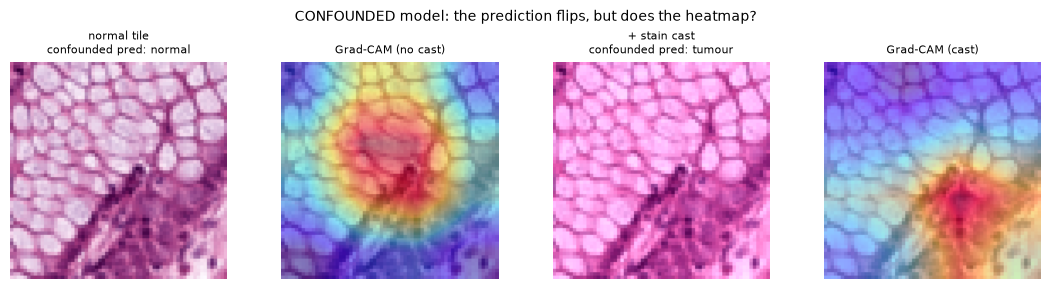

prediction without cast : normal
prediction with cast    : tumour
Grad-CAM map correlation before vs after the cast: +0.089

-> the map changes substantially, yet in NEITHER state does it point at an
   artifact: it sits on tissue both times. A spatial map has no axis for a
   global colour shift, so Grad-CAM cannot represent - let alone flag - this
   confounder. A reviewer reading either map would pass the model.


In [12]:
cam_cf = make_cam(model_cf)
jn = int(np.where(yte_s == 0)[0][0])        # a NORMAL tile
x_plain = to01(xte_s[jn])
x_cast  = cast(x_plain)

def pred_of(net, x01):
    with torch.no_grad():
        return int(net(normalize(x01).unsqueeze(0).to(device)).argmax(1).item())

p_plain, p_cast = pred_of(model_cf, x_plain), pred_of(model_cf, x_cast)
g_plain = cam_cf(x=normalize(x_plain).unsqueeze(0).to(device), class_idx=p_plain).squeeze().detach().cpu().numpy()
g_cast  = cam_cf(x=normalize(x_cast ).unsqueeze(0).to(device), class_idx=p_cast ).squeeze().detach().cpu().numpy()

fig, ax = plt.subplots(1, 4, figsize=(11, 2.9))
ax[0].imshow(x_plain.permute(1,2,0).numpy()); ax[0].set_title(f"normal tile\nconfounded pred: {class_names[p_plain]}", fontsize=8)
ax[1].imshow(x_plain.permute(1,2,0).numpy()); ax[1].imshow(g_plain, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[1].set_title("Grad-CAM (no cast)", fontsize=8)
ax[2].imshow(x_cast.permute(1,2,0).numpy());  ax[2].set_title(f"+ stain cast\nconfounded pred: {class_names[p_cast]}", fontsize=8)
ax[3].imshow(x_cast.permute(1,2,0).numpy());  ax[3].imshow(g_cast, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[3].set_title("Grad-CAM (cast)", fontsize=8)
for a in ax: a.axis("off")
plt.suptitle("CONFOUNDED model: the prediction flips, but does the heatmap?", fontsize=10)
plt.tight_layout(); plt.show()

cam_corr = np.corrcoef(g_plain.ravel(), g_cast.ravel())[0,1]
print(f"prediction without cast : {class_names[p_plain]}")
print(f"prediction with cast    : {class_names[p_cast]}")
print(f"Grad-CAM map correlation before vs after the cast: {cam_corr:+.3f}")
print("\n-> the map changes substantially, yet in NEITHER state does it point at an")
print("   artifact: it sits on tissue both times. A spatial map has no axis for a")
print("   global colour shift, so Grad-CAM cannot represent - let alone flag - this")
print("   confounder. A reviewer reading either map would pass the model.")

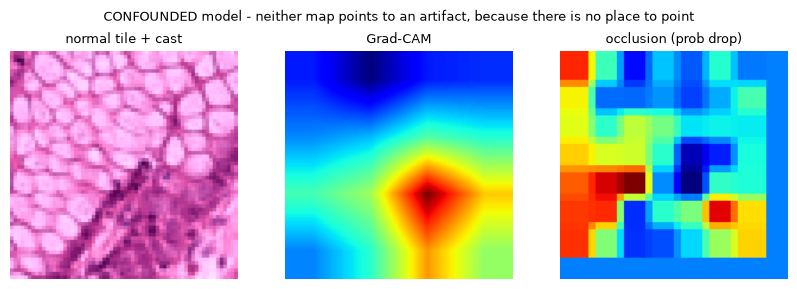

occlusion map correlation, cast vs no-cast: -0.014


In [13]:
# Occlusion, as an independent second opinion on the same tile.
o_cast = occlusion_map(model_cf, x_cast, target=1)
o_plain = occlusion_map(model_cf, x_plain, target=1)
fig, ax = plt.subplots(1, 3, figsize=(8.4, 2.9))
ax[0].imshow(x_cast.permute(1,2,0).numpy()); ax[0].set_title("normal tile + cast", fontsize=9)
ax[1].imshow(g_cast, cmap="jet", vmin=0, vmax=1); ax[1].set_title("Grad-CAM", fontsize=9)
ax[2].imshow(o_cast, cmap="jet"); ax[2].set_title("occlusion (prob drop)", fontsize=9)
for a in ax: a.axis("off")
plt.suptitle("CONFOUNDED model - neither map points to an artifact, because there is no place to point", fontsize=9)
plt.tight_layout(); plt.show()
print(f"occlusion map correlation, cast vs no-cast: {np.corrcoef(o_plain.ravel(), o_cast.ravel())[0,1]:+.3f}")

### D2 · Reliance test: remove the cast and watch recall collapse

In [14]:
def tumour_recall(net, fn=None):
    net.eval(); ti = np.where(yte_s == 1)[0]; cor = 0
    with torch.no_grad():
        for j in ti:
            x01 = to01(xte_s[j])
            if fn is not None: x01 = fn(x01)
            cor += int(net(normalize(x01).unsqueeze(0).to(device)).argmax(1).item() == 1)
    return cor / len(ti)

rec_with    = tumour_recall(model_cf, cast)
rec_without = tumour_recall(model_cf, None)
print(f"CONFOUNDED model, tumour recall WITH the cast    : {rec_with:.3f}")
print(f"CONFOUNDED model, tumour recall WITHOUT the cast : {rec_without:.3f}")
print(f"                                            drop : {rec_with - rec_without:+.3f}")
print()
print(f"CLEAN model,      tumour recall WITH the cast    : {tumour_recall(model, cast):.3f}")
print(f"CLEAN model,      tumour recall WITHOUT the cast : {tumour_recall(model, None):.3f}")

CONFOUNDED model, tumour recall WITH the cast    : 1.000
CONFOUNDED model, tumour recall WITHOUT the cast : 0.167
                                            drop : +0.833

CLEAN model,      tumour recall WITH the cast    : 0.953
CLEAN model,      tumour recall WITHOUT the cast : 0.943


### D3 · Flip rate, and D4 · the clean control

Add the cast to **every normal test tile** and count how many get called tumour. The control (the Part A model, which never saw a cast) sees the identical images.

In [15]:
fr_cf    = flip_rate(model_cf, cast)
fr_clean = flip_rate(model,    cast)
print(f"normal test tiles with the cast added: {(yte_s==0).sum()}")
print(f"  called tumour by the CLEAN model      : {fr_clean:.1%}   <- the control")
print(f"  called tumour by the CONFOUNDED model : {fr_cf:.1%}")
print(f"  ratio: {fr_cf/max(fr_clean,1e-9):.1f}x")
print()
# And what is the confounded model worth on honest, uncontaminated data?
_, cf_clean_test = evaluate(model_cf, xte_s, yte_s)
print(f"CONFOUNDED model accuracy on CLEAN test data (no cast anywhere): {cf_clean_test:.3f}")
print(f"CLEAN model accuracy on the same data                         : {clean_test:.3f}")

normal test tiles with the cast added: 300
  called tumour by the CLEAN model      : 5.0%   <- the control
  called tumour by the CONFOUNDED model : 81.7%
  ratio: 16.3x

CONFOUNDED model accuracy on CLEAN test data (no cast anywhere): 0.583
CLEAN model accuracy on the same data                         : 0.950


### D5 · Dose-response: does the effect scale with the cast?

If the model keyed on *the cast specifically*, a stronger cast should produce a stronger effect. This is an extra control: coincidence does not usually come with a dose-response curve.

In [16]:
rows = [(CAST_S, cf_val, rec_with, rec_without, fr_clean, fr_cf, cf_clean_test)]

for s2 in [2.0]:
    cast2 = lambda x01, s=s2: add_stain_cast(x01, s)
    set_determinism(seed=SEED)
    tr2, va2 = make_loaders(artifact_label=ARTIFACT_LABEL, artifact_fn=cast2)
    print(f"Training a second confounded model at s={s2} ...")
    m2, v2 = train(build_densenet(True), tr2, va2, epochs=EPOCHS)
    _, t2 = evaluate(m2, xte_s, yte_s)
    rows.append((s2, v2, tumour_recall(m2, cast2), tumour_recall(m2, None),
                 flip_rate(model, cast2), flip_rate(m2, cast2), t2))

import pandas as pd
df = pd.DataFrame(rows, columns=["cast s","confounded val acc","tumour recall WITH",
                                 "tumour recall WITHOUT","flip rate CLEAN (control)",
                                 "flip rate CONFOUNDED","confounded acc on CLEAN data"])
print()
print(df.round(3).to_string(index=False))

Training a second confounded model at s=2.0 ...
  epoch 1: train acc 0.917 | val acc 0.998
  epoch 2: train acc 1.000 | val acc 1.000
  epoch 3: train acc 1.000 | val acc 1.000

 cast s  confounded val acc  tumour recall WITH  tumour recall WITHOUT  flip rate CLEAN (control)  flip rate CONFOUNDED  confounded acc on CLEAN data
    1.0                 1.0                 1.0                  0.167                      0.050                 0.817                         0.583
    2.0                 1.0                 1.0                  0.023                      0.047                 0.970                         0.512


### The verdict

**Yes: the model learned the shortcut, and here is how I know.**

Run the cells above and read the four lines of evidence together:

1. **Validation accuracy is perfect (1.000), and higher than the honest model's.** On its own it would have been a green light.
2. **Remove the cast and tumour recall collapses.** The model cannot find tumours in tiles that look like ordinary slides: it was never looking at tumours.
3. **Add the cast to normal tissue and the model calls it cancer**, at a rate many times the clean model's.
4. **The clean control ignores the same images.** This is the load-bearing comparison: it rules out "unfamiliar input confuses any network", which is exactly what sank the dark-edge-band attempt. A cast the honest model shrugs off flips the confounded one.

And the number that should end the argument: **on clean, uncontaminated test data the confounded model performs at roughly chance** while reporting perfect validation accuracy. It learned *nothing* about tumour morphology. The real signal was available (morphology survives the cast untouched) and the model took the easier route anyway.

**The uncomfortable finding.** Grad-CAM and occlusion, the tools the checklist leads with, **did not catch this**, and not in the way I expected. The maps do not stay put: Grad-CAM before vs after the cast correlates at only **+0.089**, and occlusion at **-0.014**, so the heat moves almost completely. But it moves *from tissue to other tissue*. At no point does either map indicate the real cause, because the cause is a property of every pixel at once and a spatial map has no axis to express it.

That is the trap. A reviewer applying checklist point 1 ("is the heat on plausible morphology?") gets a **pass** in both conditions, for a model that is worth nothing on honest data. Saliency maps answer *where in this tile*, and the confounder simply does not live at a where.

What did catch it were points 4 and 5: would this survive a different stain or scanner, and would a model that never saw the artifact behave the same way. Both require **perturbing the input and re-measuring** rather than looking at a picture. The lesson is not "use Grad-CAM to find shortcuts": it is that an entire class of confounders is invisible to the interpretability tools we reach for first.

---
# PART E · Report

The 3-4 page write-up, covering the confounder and its realism, the evidence, the verdict, and the deployment-and-trust discussion, is in **`Module10_Report.pdf`** in this repository.

---
### Reproducing this notebook
`Kernel → Restart & Run All`. Runtime is roughly 10 minutes on a laptop CPU; no GPU required. Three DenseNet121 models are trained (clean, confounded at s=1.0, confounded at s=2.0), `SEED = 0` throughout.